# Question 4: Predicting next-step transaction volume

The model is trained: fitted on the earliest 70% of the pairs and judged on the
remaining 30%, which it never saw.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import csc1105 as cs

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.4


In [2]:
analysis_df = cs.load_clean(verbose=False)
counts = analysis_df.groupby("step").size().sort_index()
steps = counts.index.to_numpy()
print("steps:", steps.min(), "to", steps.max(), " distinct:", len(steps))

steps: 0 to 143  distinct: 144


## 4(a) Are the steps consecutive?

A gap has two readings: the hour existed and nothing happened (a true zero), or
the simulation produced nothing comparable (inserting a zero invents data).
Investigate before deciding.

In [3]:
gaps = np.diff(steps)
print("distinct gaps between consecutive steps:", np.unique(gaps))
if (gaps == 1).all():
    print("-> steps are consecutive, nothing to decide")
else:
    missing = np.setdiff1d(np.arange(steps.min(), steps.max() + 1), steps)
    print("-> missing steps:", missing[:20], "..." if len(missing) > 20 else "")
    print("   decide whether these are zero-count hours, record the decision,")
    print("   and only then uncomment the reindex below")
# counts = counts.reindex(np.arange(steps.min(), steps.max()+1), fill_value=0)

distinct gaps between consecutive steps: [1]
-> steps are consecutive, nothing to decide


In [4]:
c = counts.to_numpy(dtype=float)
c_in, c_out = c[:-1], c[1:]
m = len(c_in)
k = int(np.floor(0.70 * m))

A = np.column_stack([np.ones(m), c_in])
A_tr, y_tr = A[:k], c_out[:k]
A_te, y_te = A[k:], c_out[k:]

target_steps = counts.index.to_numpy()[1:]
print(f"pairs            : {m}")
print(f"split boundary k : {k}  (train {k}, test {m-k})")
print(f"last training target step : {target_steps[k-1]}")
print(f"first test target step    : {target_steps[k]}")
print()
print("A_train", A_tr.shape, " y_train", y_tr.shape)
print("A_test ", A_te.shape, " y_test ", y_te.shape)

pairs            : 143
split boundary k : 100  (train 100, test 43)
last training target step : 100
first test target step    : 101

A_train (100, 2)  y_train (100,)
A_test  (43, 2)  y_test  (43,)


**Why not a random split.** The task is predicting the future. A random split
would train on pairs that come *after* pairs it is then tested on, so the
reported error would be better than the model could ever achieve in use, where
the future is not available. A chronological split reproduces the real
situation: fit on the past, apply to the next hour.

## 4(b) Train by least squares

`A @ beta = y` has no exact solution, so least squares makes the residual
`r = y - A @ beta` as short as possible. The shortest residual is the one
orthogonal to every column of A, which gives `A.T @ r = 0` and hence the normal
equations `A.T @ A @ beta = A.T @ y`.

In [5]:
AtA, Aty = A_tr.T @ A_tr, A_tr.T @ y_tr
print("A.T @ A =\n", AtA)
print("A.T @ y =", Aty)
print("det     =", np.linalg.det(AtA), " (nonzero, so the fit is defined)")

beta, *_ = np.linalg.lstsq(A_tr, y_tr, rcond=None)
print()
print(f"intercept beta_0 = {beta[0]:.6f}")
print(f"slope     beta_1 = {beta[1]:.6f}")
print("normal equations agree:",
      np.allclose(beta, np.linalg.solve(AtA, Aty)))

A.T @ A =
 [[1.00000000e+02 1.24243200e+06]
 [1.24243200e+06 2.01524905e+10]]
A.T @ y = [1.24398800e+06 1.97478764e+10]
det     = 471611772576.0  (nonzero, so the fit is defined)

intercept beta_0 = 1132.420370
slope     beta_1 = 0.910107
normal equations agree: True


`y_hat = A_test @ beta` is `beta_0` times the column of ones plus `beta_1` times
the column of test inputs, so every prediction the model can make lies in the
span of those two columns, a two-dimensional subspace. The observed vector
almost certainly lies outside it, and that difference is the error.

In [6]:
y_hat = A_te @ beta
base = A_te[:, 1]            # persistence: next hour repeats this hour

def metrics(y, pred):
    e = y - pred
    return np.abs(e).mean(), np.sqrt((e ** 2).mean())

mae_m, rmse_m = metrics(y_te, y_hat)
mae_b, rmse_b = metrics(y_te, base)

print(f"{'':10s} {'MAE':>12s} {'RMSE':>12s}")
print(f"{'model':10s} {mae_m:12.4f} {rmse_m:12.4f}")
print(f"{'baseline':10s} {mae_b:12.4f} {rmse_b:12.4f}")
print()
print(f"MAE  change vs baseline: {100*(mae_m-mae_b)/mae_b:+.1f}%")
print(f"RMSE change vs baseline: {100*(rmse_m-rmse_b)/rmse_b:+.1f}%")
print()
print("the model beats the baseline:" , bool(mae_m < mae_b and rmse_m < rmse_b))

                    MAE         RMSE
model         1424.9284    2529.2351
baseline      1273.6047    2605.2769

MAE  change vs baseline: +11.9%
RMSE change vs baseline: -2.9%

the model beats the baseline: False


## 4(c) Plot and discussion

saved C:\Math 2026 repo\CSC-1105-Maths-for-CS\figures\forecast.png


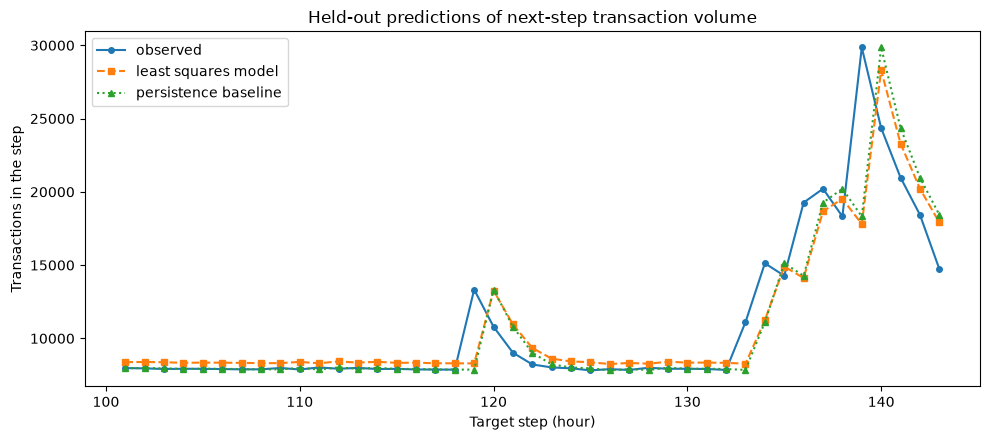

In [7]:
ts = target_steps[k:]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ts, y_te, "o-", label="observed", markersize=4)
ax.plot(ts, y_hat, "s--", label="least squares model", markersize=4)
ax.plot(ts, base, "^:", label="persistence baseline", markersize=4)
ax.set_xlabel("Target step (hour)")
ax.set_ylabel("Transactions in the step")
ax.set_title("Held-out predictions of next-step transaction volume")
ax.legend()
cs.savefig(fig, "forecast.png")
plt.show()

### Discussion

The error connects to the decision. An MAE of a given size means the count for
the next hour is typically wrong by about that many transactions.
Under-prediction leaves too few staff, so queues build. Over-prediction wastes
staff time. The two do not cost the same, so if one is worse, plan to the
prediction plus a margin related to the RMSE rather than the prediction alone.

Two limitations apply: the model uses only the previous count, so it cannot
anticipate a change not already visible in that number; and it was fitted on the
earliest 70%, so if behaviour shifts later the coefficients are out of date and
it would need refitting as new steps arrive.